# Airbnb Listings Analysis: Chicago vs New Orleans

**Project:** Comparative EDA and dashboard support for Airbnb listings in Chicago and New Orleans  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Dashboard:** Power BI (Overview, Property Analysis, Pricing Analysis, Host Analysis)

## Objective
Compare listing supply, neighbourhood distribution, property and room types, pricing patterns, review activity, and host characteristics across the two cities.

> **Important:** This notebook analyzes listing-level snapshot data. `availability_365` means days a listing is available on the calendar; it is **not** booked nights or occupancy. Listing price is not Airbnb revenue.


## 1. Import libraries and upload source files

Upload the two original `.csv.gz` files when prompted:
- `Chicago.csv.gz` — Chicago
- `New Orleans.csv.gz` — New Orleans

If your downloaded filenames differ, the code identifies the files by their names containing `listings`.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from pathlib import Path
import io, gzip, re, os

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving New Orleans.csv.gz to New Orleans.csv (1).gz
Saving Chicago.csv.gz to Chicago.csv (1).gz
Uploaded files: ['New Orleans.csv (1).gz', 'Chicago.csv (1).gz']


## 2. Load both city datasets

The source files use the same Inside Airbnb-style schema. We attach a `city` field before combining them.


In [8]:
def find_upload(keyword):
    matches = [name for name in uploaded if keyword.lower() in name.lower()]
    if not matches:
        raise FileNotFoundError(
            f"Could not find a file containing '{keyword}'. Uploaded: {list(uploaded)}"
        )
    return matches[0]

# Match the original source filenames; change these two names if necessary.
chicago_file = find_upload("Chicago.csv")
new_orleans_file = find_upload("New Orleans")

chicago_raw = pd.read_csv(io.BytesIO(uploaded[chicago_file]), compression="gzip", low_memory=False)
new_orleans_raw = pd.read_csv(io.BytesIO(uploaded[new_orleans_file]), compression="gzip", low_memory=False)

chicago_raw["city"] = "Chicago"
new_orleans_raw["city"] = "New Orleans"

print("Chicago shape:", chicago_raw.shape)
print("New Orleans shape:", new_orleans_raw.shape)
display(chicago_raw.head(3))

Chicago shape: (8695, 91)
New Orleans shape: (7263, 91)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,city
0,992586867429228073,https://www.airbnb.com/rooms/992586867429228073,20260919134040,2026-09-19,NaN,Large bedroom Chicago Southside,This stylish place to stay is perfect for grou...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,536176286,...,NaN,NaN,NaN,NaN,1,0,1,0,NaN,Chicago
1,781756975718097383,https://www.airbnb.com/rooms/781756975718097383,20260919134040,2026-09-20,NaN,Lake Loop University of Chicago,Take it easy at this unique and tranquil getaw...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,481531926,...,NaN,NaN,NaN,NaN,1,1,0,0,NaN,Chicago
2,1302498659858454372,https://www.airbnb.com/rooms/1302498659858454372,20260919134040,2026-09-20,NaN,"J44. noisy room, next Downtown",Enjoy a stylish experience at this centrally-l...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,220441747,...,4.04,4.58,R25000129028,NaN,10,1,9,0,1.11,Chicago


## 3. Select relevant columns and standardize field names

Only fields needed for the comparison and Power BI dashboard are retained. The original `id` is renamed to `listing_id`.


In [9]:
column_map = {
    "id": "listing_id",
    "name": "listing_name",
    "host_listings_count": "host_listing_count",
    "calculated_host_listings_count": "host_calculated_listing_count",
    "neighbourhood_cleansed": "neighbourhood",
    "host_is_superhost": "host_is_superhost",
    "price": "price",
    "last_scraped": "snapshot_date"
}

wanted = [
    "id", "name", "host_id", "host_name", "neighbourhood_cleansed",
    "latitude", "longitude", "property_type", "room_type", "accommodates",
    "bedrooms", "beds", "price", "minimum_nights", "number_of_reviews",
    "last_review", "reviews_per_month", "availability_365",
    "host_listings_count", "calculated_host_listings_count",
    "host_is_superhost", "host_response_time", "host_response_rate",
    "instant_bookable", "review_scores_rating", "last_scraped"
]

def select_and_standardize(df):
    available = [c for c in wanted if c in df.columns]
    out = df[available + ["city"]].copy()
    out = out.rename(columns=column_map)
    if "host_listing_count" not in out.columns and "host_calculated_listing_count" in out.columns:
        out["host_listing_count"] = out["host_calculated_listing_count"]
    if "host_listing_count" in out.columns and "host_calculated_listing_count" in out.columns:
        out["host_listing_count"] = out["host_listing_count"].fillna(out["host_calculated_listing_count"])
        out = out.drop(columns=["host_calculated_listing_count"])
    return out

chicago = select_and_standardize(chicago_raw)
new_orleans = select_and_standardize(new_orleans_raw)
df = pd.concat([chicago, new_orleans], ignore_index=True)

print("Combined shape:", df.shape)
display(df.head())

Combined shape: (15958, 26)


,listing_id,listing_name,host_id,host_name,neighbourhood,latitude,longitude,property_type,room_type,accommodates,...,reviews_per_month,availability_365,host_listing_count,host_is_superhost,host_response_time,host_response_rate,instant_bookable,review_scores_rating,snapshot_date,city
0,992586867429228073,Large bedroom Chicago Southside,536176286,Teasia,Burnside,41.728400,-87.598490,Private room in rental unit,Private room,2,...,NaN,269,1,f,NaN,NaN,NaN,NaN,2026-09-19,Chicago
1,781756975718097383,Lake Loop University of Chicago,481531926,Magdalena,Oakland,41.828240,-87.604510,Entire rental unit,Entire home/apt,4,...,NaN,357,1,f,NaN,NaN,NaN,NaN,2026-09-20,Chicago
2,1302498659858454372,"J44. noisy room, next Downtown",220441747,Sergio,East Garfield Park,41.874540,-87.692620,Private room in rental unit,Private room,2,...,1.11,160,10,f,NaN,NaN,NaN,4.5,2026-09-20,Chicago
3,1693891002681508102,Near McCormick Place - Modern 1 Bed & fold out,711712599,Ray,Near South Side,41.846941,-87.617569,Entire rental unit,Entire home/apt,3,...,NaN,329,2,f,NaN,NaN,NaN,NaN,2026-09-20,Chicago
4,1675783224828050214,Near Halsted Orange Line CTA & McCormick Pl,436959191,Yan Na,Bridgeport,41.844960,-87.644550,Private room in home,Private room,1,...,NaN,275,11,f,NaN,NaN,NaN,NaN,2026-09-20,Chicago


## 4. Data cleaning and transformation

- Remove duplicate listing IDs within each city.
- Trim text fields.
- Convert price strings such as `$125.00` to numeric values.
- Treat zero/negative prices as missing, not as free listings.
- Convert numeric fields and dates to appropriate data types.
- Keep missing prices as null values; do not replace them with zero.
- Validate availability values to the expected 0–365 range.


In [10]:
# Remove duplicate listing IDs within each city
before = len(df)
df = df.drop_duplicates(subset=["city", "listing_id"]).copy()
print("Duplicate rows removed:", before - len(df))

# Trim text columns
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)

# Clean numeric price
if "price" in df.columns:
    df["price"] = (
        df["price"].astype(str)
        .str.replace(r"[$,]", "", regex=True)
        .replace({"nan": np.nan, "None": np.nan, "": np.nan})
    )
    df["price"] = pd.to_numeric(df["price"], errors="coerce")
    df.loc[df["price"] <= 0, "price"] = np.nan

numeric_cols = [
    "latitude", "longitude", "accommodates", "bedrooms", "beds",
    "minimum_nights", "number_of_reviews", "reviews_per_month",
    "availability_365", "host_listing_count", "review_scores_rating"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "availability_365" in df.columns:
    df.loc[~df["availability_365"].between(0, 365), "availability_365"] = np.nan

for col in ["last_review", "snapshot_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Standardize boolean-like fields
if "host_is_superhost" in df.columns:
    df["host_is_superhost"] = df["host_is_superhost"].replace({
        "t": "Yes", "f": "No", "True": "Yes", "False": "No"
    })
if "instant_bookable" in df.columns:
    df["instant_bookable"] = df["instant_bookable"].replace({
        "t": "Yes", "f": "No", "True": "Yes", "False": "No"
    })

print("Cleaned shape:", df.shape)
display(df.head())

Duplicate rows removed: 0
Cleaned shape: (15958, 26)


,listing_id,listing_name,host_id,host_name,neighbourhood,latitude,longitude,property_type,room_type,accommodates,...,reviews_per_month,availability_365,host_listing_count,host_is_superhost,host_response_time,host_response_rate,instant_bookable,review_scores_rating,snapshot_date,city
0,992586867429228073,Large bedroom Chicago Southside,536176286,Teasia,Burnside,41.728400,-87.598490,Private room in rental unit,Private room,2,...,NaN,269.0,1,No,NaN,NaN,NaN,NaN,2026-09-19,Chicago
1,781756975718097383,Lake Loop University of Chicago,481531926,Magdalena,Oakland,41.828240,-87.604510,Entire rental unit,Entire home/apt,4,...,NaN,357.0,1,No,NaN,NaN,NaN,NaN,2026-09-20,Chicago
2,1302498659858454372,"J44. noisy room, next Downtown",220441747,Sergio,East Garfield Park,41.874540,-87.692620,Private room in rental unit,Private room,2,...,1.11,160.0,10,No,NaN,NaN,NaN,4.5,2026-09-20,Chicago
3,1693891002681508102,Near McCormick Place - Modern 1 Bed & fold out,711712599,Ray,Near South Side,41.846941,-87.617569,Entire rental unit,Entire home/apt,3,...,NaN,329.0,2,No,NaN,NaN,NaN,NaN,2026-09-20,Chicago
4,1675783224828050214,Near Halsted Orange Line CTA & McCormick Pl,436959191,Yan Na,Bridgeport,41.844960,-87.644550,Private room in home,Private room,1,...,NaN,275.0,11,No,NaN,NaN,NaN,NaN,2026-09-20,Chicago


## 5. Data quality checks

Review missing values, duplicate IDs, price validity, and city-level record counts before analysis.


In [11]:
quality = df.groupby("city").agg(
    total_listings=("listing_id", "count"),
    unique_hosts=("host_id", "nunique"),
    unique_neighbourhoods=("neighbourhood", "nunique"),
    missing_price=("price", lambda s: s.isna().sum()),
    price_missing_pct=("price", lambda s: round(s.isna().mean() * 100, 2)),
    duplicate_listing_ids=("listing_id", lambda s: s.duplicated().sum())
).reset_index()

display(quality)
print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count").head(15))

,city,total_listings,unique_hosts,unique_neighbourhoods,missing_price,price_missing_pct,duplicate_listing_ids
0,Chicago,8695,3635,76,1243,14.30,0
1,New Orleans,7263,3208,70,1073,14.77,0



Missing values by column:


,missing_count
instant_bookable,15958
host_response_time,15958
host_response_rate,15958
reviews_per_month,2644
last_review,2644
review_scores_rating,2644
price,2316
beds,450
minimum_nights,234
bedrooms,3


## 6. Feature engineering

These price, review, availability, and host groupings are analytical buckets created for this project. They are not official Airbnb classifications.


In [12]:
df["Price Category"] = pd.cut(
    df["price"],
    bins=[-np.inf, 50, 100, 200, 400, np.inf],
    labels=["Budget", "Economy", "Mid-Range", "Premium", "Luxury"]
).astype("object")
df.loc[df["price"].isna(), "Price Category"] = "Unknown"

df["Availability Category"] = pd.cut(
    df["availability_365"],
    bins=[-1, 30, 180, 365],
    labels=["Low", "Medium", "High"]
).astype("object")
df.loc[df["availability_365"].isna(), "Availability Category"] = "Unknown"

df["Host Category"] = np.select(
    [
        df["host_listing_count"].isna(),
        df["host_listing_count"].eq(1),
        df["host_listing_count"].le(5)
    ],
    ["Unknown", "Single Listing Host", "Small Host"],
    default="Multi-Listing Host"
)

df["Review Category"] = np.select(
    [
        df["number_of_reviews"].isna(),
        df["number_of_reviews"].eq(0),
        df["number_of_reviews"].le(10),
        df["number_of_reviews"].le(50)
    ],
    ["Unknown", "No Reviews", "Low Reviews", "Medium Reviews"],
    default="High Reviews"
)

display(df[["city", "price", "Price Category", "availability_365",
            "Availability Category", "host_listing_count", "Host Category"]].head())

,city,price,Price Category,availability_365,Availability Category,host_listing_count,Host Category
0,Chicago,177.33,Mid-Range,269.0,High,1,Single Listing Host
1,Chicago,NaN,Unknown,357.0,High,1,Single Listing Host
2,Chicago,50.77,Economy,160.0,Medium,10,Multi-Listing Host
3,Chicago,140.14,Mid-Range,329.0,High,2,Small Host
4,Chicago,45.06,Budget,275.0,High,11,Multi-Listing Host


## 7. Overview: listing supply and city comparison

,city,total_listings,unique_hosts,average_price,median_price,average_reviews,average_availability
0,Chicago,8695,3635,293.31,208.92,65.19,224.78
1,New Orleans,7263,3208,282.81,197.28,72.19,216.88


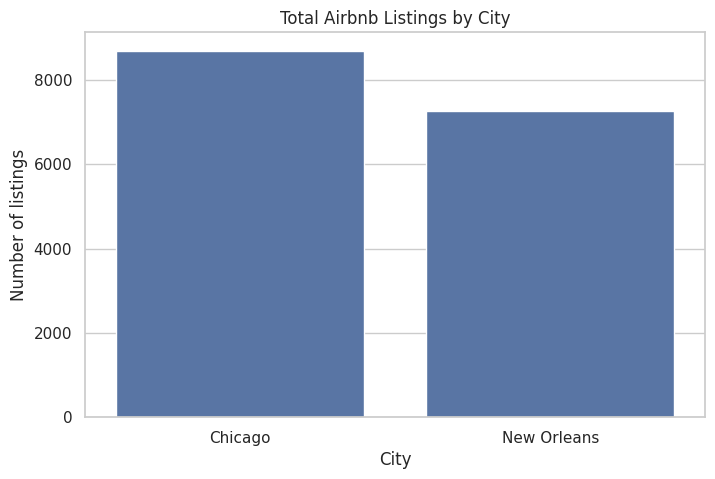

In [13]:
city_summary = df.groupby("city").agg(
    total_listings=("listing_id", "count"),
    unique_hosts=("host_id", "nunique"),
    average_price=("price", "mean"),
    median_price=("price", "median"),
    average_reviews=("number_of_reviews", "mean"),
    average_availability=("availability_365", "mean")
).round(2).reset_index()

display(city_summary)

plt.figure(figsize=(8, 5))
sns.barplot(data=city_summary, x="city", y="total_listings")
plt.title("Total Airbnb Listings by City")
plt.xlabel("City"); plt.ylabel("Number of listings")
plt.show()

## 8. Property analysis: room types and property types

,city,room_type,listings
0,Chicago,Entire home/apt,6723
2,Chicago,Private room,1854
1,Chicago,Hotel room,83
3,Chicago,Shared room,35
4,New Orleans,Entire home/apt,5776
6,New Orleans,Private room,1284
5,New Orleans,Hotel room,193
7,New Orleans,Shared room,10


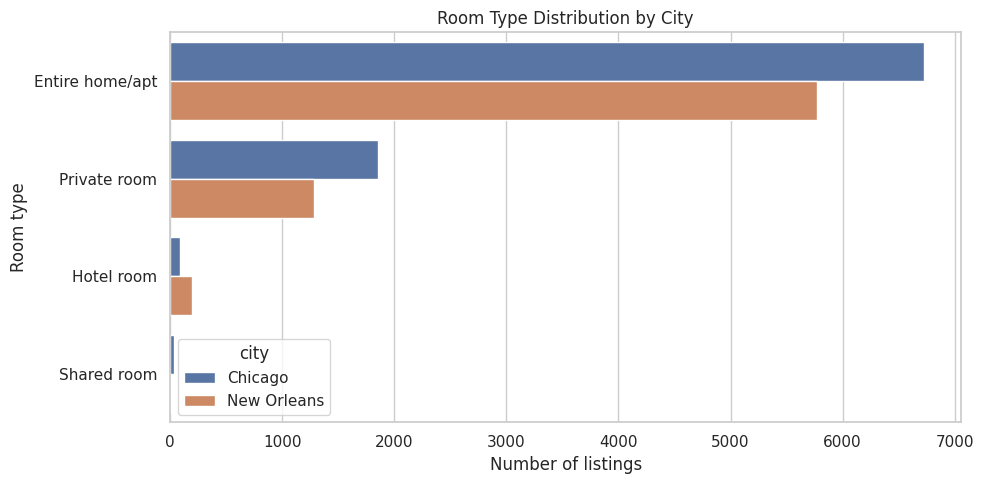

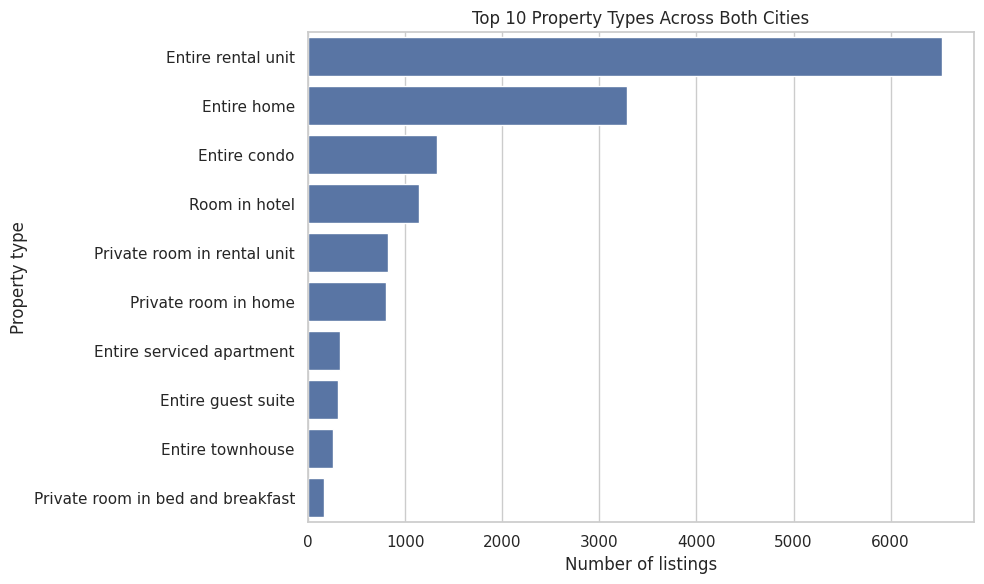

In [14]:
room_mix = df.groupby(["city", "room_type"], dropna=False).size().reset_index(name="listings")
display(room_mix.sort_values(["city", "listings"], ascending=[True, False]))

plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="room_type", hue="city",
              order=df["room_type"].value_counts().index)
plt.title("Room Type Distribution by City")
plt.xlabel("Number of listings"); plt.ylabel("Room type")
plt.tight_layout(); plt.show()

top_property = df["property_type"].value_counts().head(10).index
plt.figure(figsize=(10, 6))
sns.countplot(data=df[df["property_type"].isin(top_property)],
              y="property_type", order=top_property)
plt.title("Top 10 Property Types Across Both Cities")
plt.xlabel("Number of listings"); plt.ylabel("Property type")
plt.tight_layout(); plt.show()

## 9. Neighbourhood analysis

Top neighbourhoods — Chicago


,city,neighbourhood,listings,average_price,median_price
47,Chicago,Near North Side,1019,433.998703,298.250
74,Chicago,West Town,790,356.297219,256.620
41,Chicago,Loop,604,507.673445,347.730
49,Chicago,Near West Side,601,355.519241,244.390
37,Chicago,Lake View,557,329.994250,238.145
40,Chicago,Logan Square,421,251.326185,192.500
38,Chicago,Lincoln Park,282,387.302471,300.000
75,Chicago,Woodlawn,251,177.949779,116.490
42,Chicago,Lower West Side,246,191.907556,164.500
48,Chicago,Near South Side,225,320.034863,255.000


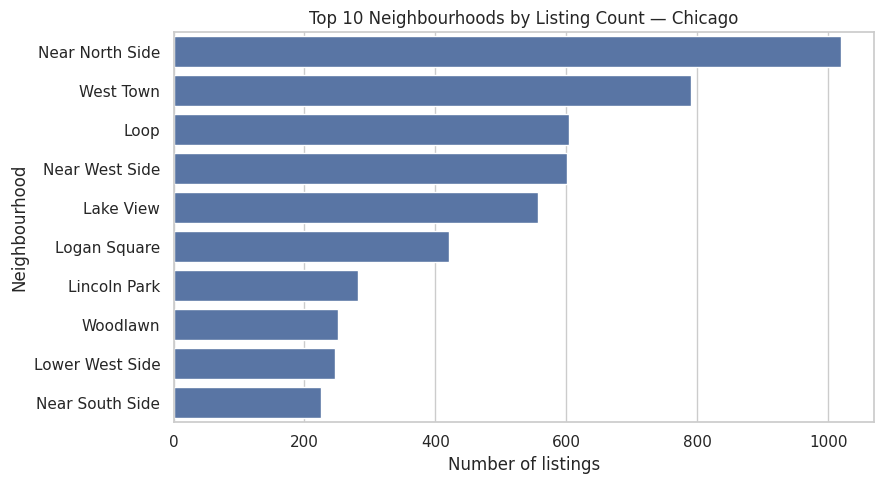

Top neighbourhoods — New Orleans


,city,neighbourhood,listings,average_price,median_price
84,New Orleans,Central Business District,1476,337.062487,223.300
85,New Orleans,Central City,654,340.135302,203.270
114,New Orleans,Marigny,416,316.228011,205.720
117,New Orleans,Mid-City,381,241.051875,193.600
128,New Orleans,Seventh Ward,379,223.846786,171.515
136,New Orleans,Treme - Lafitte,365,288.405884,159.000
96,New Orleans,French Quarter,304,289.151625,205.830
131,New Orleans,St. Claude,291,247.099049,234.000
112,New Orleans,Lower Garden District,284,356.930857,236.000
83,New Orleans,Bywater,202,257.520568,195.540


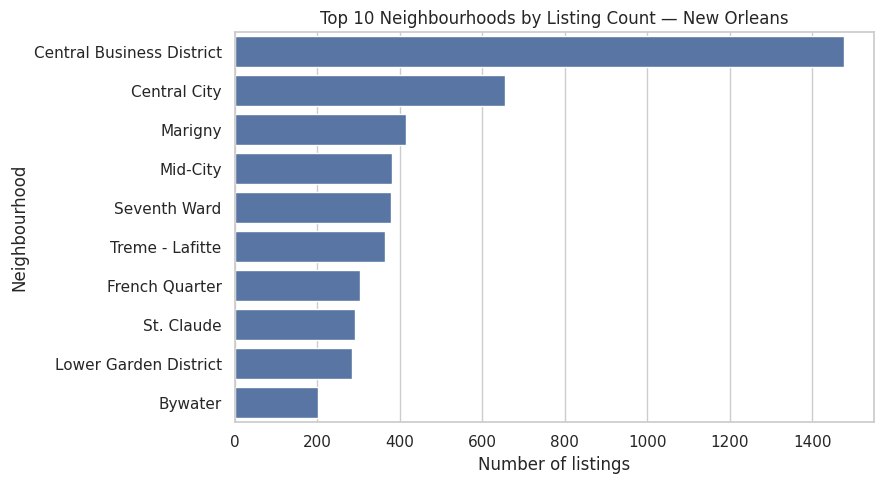

In [15]:
neighbourhood_summary = df.groupby(["city", "neighbourhood"], dropna=False).agg(
    listings=("listing_id", "count"),
    average_price=("price", "mean"),
    median_price=("price", "median")
).reset_index()

for city in df["city"].dropna().unique():
    top = (neighbourhood_summary[neighbourhood_summary["city"] == city]
           .sort_values("listings", ascending=False).head(10))
    print(f"Top neighbourhoods — {city}")
    display(top)

    plt.figure(figsize=(9, 5))
    sns.barplot(data=top, y="neighbourhood", x="listings")
    plt.title(f"Top 10 Neighbourhoods by Listing Count — {city}")
    plt.xlabel("Number of listings"); plt.ylabel("Neighbourhood")
    plt.tight_layout(); plt.show()

## 10. Pricing analysis

Price statistics exclude missing prices. Median is included because average prices can be influenced by unusually expensive listings.


,city,listing_count,mean_price,median_price
0,Chicago,7452,293.31,208.92
1,New Orleans,6190,282.81,197.28


,city,room_type,average_price,median_price,listings_with_price
0,Chicago,Entire home/apt,337.30,238.50,5740
1,Chicago,Hotel room,397.28,299.00,80
2,Chicago,Private room,135.05,85.00,1601
3,Chicago,Shared room,52.84,41.78,31
4,New Orleans,Entire home/apt,287.65,202.75,4901
5,New Orleans,Hotel room,434.99,274.50,179
6,New Orleans,Private room,238.39,169.00,1102
7,New Orleans,Shared room,31.20,23.18,8


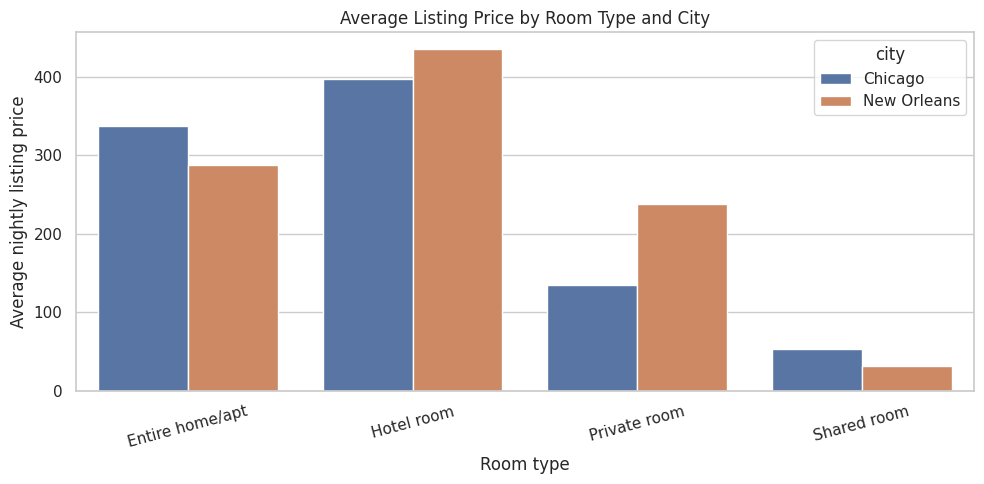

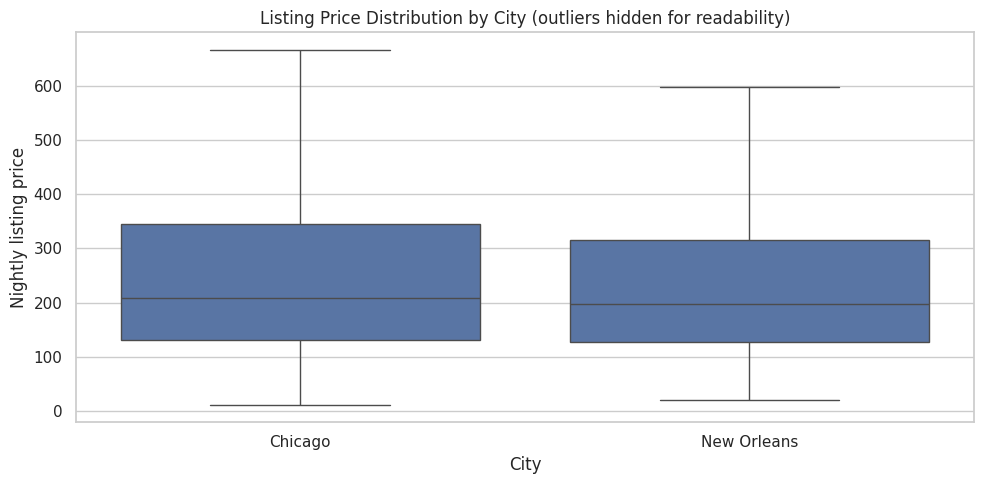

In [16]:
price_by_city = df.groupby("city")["price"].agg(
    listing_count="count", mean_price="mean", median_price="median"
).round(2).reset_index()
display(price_by_city)

room_price = df.groupby(["city", "room_type"])["price"].agg(
    average_price="mean", median_price="median", listings_with_price="count"
).round(2).reset_index()
display(room_price)

plt.figure(figsize=(10, 5))
sns.barplot(data=room_price, x="room_type", y="average_price", hue="city")
plt.title("Average Listing Price by Room Type and City")
plt.xlabel("Room type"); plt.ylabel("Average nightly listing price")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="city", y="price", showfliers=False)
plt.title("Listing Price Distribution by City (outliers hidden for readability)")
plt.xlabel("City"); plt.ylabel("Nightly listing price")
plt.tight_layout(); plt.show()

## 11. Reviews and host analysis

,city,Host Category,listings,unique_hosts,average_price,average_reviews,average_rating
0,Chicago,Multi-Listing Host,4394,416,318.74,48.57,4.72
1,Chicago,Single Listing Host,2234,2234,280.51,85.36,4.84
2,Chicago,Small Host,2067,985,257.38,78.73,4.78
3,New Orleans,Multi-Listing Host,3424,325,330.53,58.86,4.73
4,New Orleans,Single Listing Host,2039,2039,226.72,86.91,4.86
5,New Orleans,Small Host,1800,844,243.09,80.88,4.79


,city,listings,listings_with_reviews,average_review_count,average_reviews_per_month,average_rating
0,Chicago,8695,8695,65.19,2.02,4.77
1,New Orleans,7263,7263,72.19,1.69,4.78


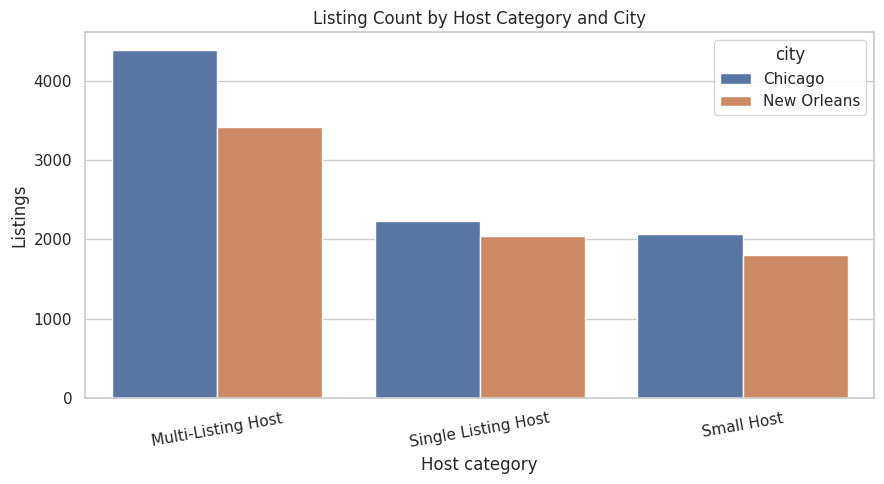

In [17]:
host_summary = df.groupby(["city", "Host Category"], dropna=False).agg(
    listings=("listing_id", "count"),
    unique_hosts=("host_id", "nunique"),
    average_price=("price", "mean"),
    average_reviews=("number_of_reviews", "mean"),
    average_rating=("review_scores_rating", "mean")
).round(2).reset_index()
display(host_summary)

review_summary = df.groupby("city").agg(
    listings=("listing_id", "count"),
    listings_with_reviews=("number_of_reviews", lambda s: s.notna().sum()),
    average_review_count=("number_of_reviews", "mean"),
    average_reviews_per_month=("reviews_per_month", "mean"),
    average_rating=("review_scores_rating", "mean")
).round(2).reset_index()
display(review_summary)

plt.figure(figsize=(9, 5))
sns.barplot(data=host_summary, x="Host Category", y="listings", hue="city")
plt.title("Listing Count by Host Category and City")
plt.xlabel("Host category"); plt.ylabel("Listings")
plt.xticks(rotation=10); plt.tight_layout(); plt.show()

## 12. Relationship exploration

Correlation is calculated only for numeric fields. Correlation does not establish causation.


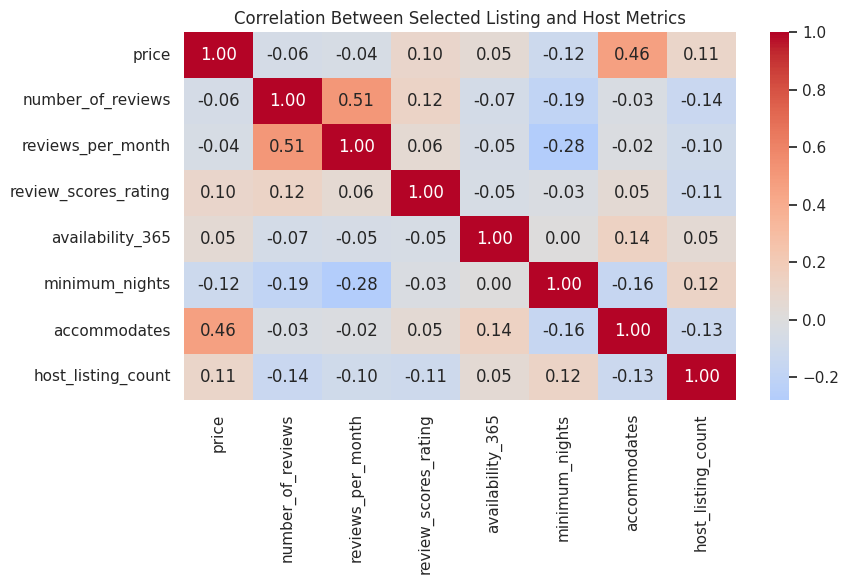

,price,number_of_reviews,reviews_per_month,review_scores_rating,availability_365,minimum_nights,accommodates,host_listing_count
price,1.00,-0.06,-0.04,0.10,0.05,-0.12,0.46,0.11
number_of_reviews,-0.06,1.00,0.51,0.12,-0.07,-0.19,-0.03,-0.14
reviews_per_month,-0.04,0.51,1.00,0.06,-0.05,-0.28,-0.02,-0.10
review_scores_rating,0.10,0.12,0.06,1.00,-0.05,-0.03,0.05,-0.11
availability_365,0.05,-0.07,-0.05,-0.05,1.00,0.00,0.14,0.05
minimum_nights,-0.12,-0.19,-0.28,-0.03,0.00,1.00,-0.16,0.12
accommodates,0.46,-0.03,-0.02,0.05,0.14,-0.16,1.00,-0.13
host_listing_count,0.11,-0.14,-0.10,-0.11,0.05,0.12,-0.13,1.00


In [18]:
numeric_for_corr = [
    c for c in ["price", "number_of_reviews", "reviews_per_month",
                "review_scores_rating", "availability_365",
                "minimum_nights", "accommodates", "host_listing_count"]
    if c in df.columns
]
corr = df[numeric_for_corr].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Between Selected Listing and Host Metrics")
plt.tight_layout(); plt.show()

display(corr.round(2))

## 13. Key findings and business interpretation

Use the tables and charts above to write the final city-specific findings. Do not assume one city is better based only on listing count or average price.

Suggested interpretation prompts:
- Which city has more listings and more unique hosts?
- Which room types dominate each market?
- Which neighbourhoods have the highest listing concentration?
- How do average and median prices differ?
- Do host categories show differences in average price, review count, or rating?
- Are there data-quality limitations that could affect interpretation?

**Limitations**
1. The two city datasets were scraped on different dates, so this is not a perfectly synchronized snapshot.
2. Price is missing for a meaningful share of listings; price comparisons use only available prices.
3. Availability is calendar availability, not actual occupancy or bookings.
4. Review counts are cumulative listing-level measures and do not directly represent current demand.
5. Correlation is descriptive and does not imply causation.


## 14. Export the cleaned dataset for Power BI

This exports the standardized dataset with the same core fields and engineered categories used in the dashboard. Download the CSV and use it as the Power BI source if needed.


In [19]:
output_file = "airbnb_chicago_new_orleans_cleaned_from_colab.csv"
df.to_csv(output_file, index=False)
print("Saved:", output_file)
files.download(output_file)

Saved: airbnb_chicago_new_orleans_cleaned_from_colab.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

This notebook combines and prepares the two city datasets, explores listing supply, property and room types, neighbourhood concentration, pricing, reviews, and host characteristics, and exports a cleaned dataset for dashboarding.

The Power BI report presents these comparisons across four pages: **Overview, Property Analysis, Pricing Analysis, and Host Analysis**. Findings should be interpreted in light of the snapshot-date and missing-price limitations described above.
